In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sklearn as sk #ML linear regresssion
from sklearn.linear_model import LinearRegression
from sklearn.datasets import load_diabetes
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import KFold, cross_
dataset1= load_diabetes()
dataset2= fetch_california_housing()


In [ ]:
x1=dataset1.data
y1=dataset1.target

print(x1.shape)
print(y1.shape)
print(dataset1.feature_names)

(442, 10)
(442,)
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


In [ ]:
x2=dataset1.data
y2=dataset1.target
print(x2.shape)
print(y2.shape)
print(dataset2.feature_names)


(442, 10)
(442,)
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [ ]:
df2 = pd.DataFrame(x1, columns=dataset1.feature_names)
print(df2.head())

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  


In [ ]:
df2["limit"]=dataset1.target
print(df2)

          age       sex       bmi        bp        s1        s2        s3  \
0    0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1   -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2    0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3   -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4    0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   
..        ...       ...       ...       ...       ...       ...       ...   
437  0.041708  0.050680  0.019662  0.059744 -0.005697 -0.002566 -0.028674   
438 -0.005515  0.050680 -0.015906 -0.067642  0.049341  0.079165 -0.028674   
439  0.041708  0.050680 -0.015906  0.017293 -0.037344 -0.013840 -0.024993   
440 -0.045472 -0.044642  0.039062  0.001215  0.016318  0.015283 -0.028674   
441 -0.045472 -0.044642 -0.073030 -0.081413  0.083740  0.027809  0.173816   

           s4        s5        s6  limit  
0   -0.002592  0.019907 -0.01764

In [ ]:

y_col = df2['bmi']
print(y_col)


0      0.061696
1     -0.051474
2      0.044451
3     -0.011595
4     -0.036385
         ...   
437    0.019662
438   -0.015906
439   -0.015906
440    0.039062
441   -0.073030
Name: bmi, Length: 442, dtype: float64


In [ ]:
# 1. Extract BMI as a 2D DataFrame (Notice the double brackets [[ ]])
X_bmi = df2[['bmi']]

# 2. Extract the Target (Disease progression score from dataset1)
y_target = dataset1.target

# Check their structures
print(f"X_bmi structure: {X_bmi.shape}")
print(f"y_target structure: {y_target.shape}")


X_bmi structure: (442, 1)
y_target structure: (442,)


In [ ]:
from sklearn.model_selection import train_test_split
# Split into 70% training data and 30% test data
X_train, X_test, y_train, y_test = train_test_split(
    X_bmi,
    y_target,
    test_size=0.3, #test data size is 30%
    random_state=42 #randomly chooses data for both test and train
)

# Verify the splits
print(f"Training features size: {X_train.shape}")
print(f"Testing features size:  {X_test.shape}")

Training features size: (309, 1)
Testing features size:  (133, 1)


In [ ]:
lr = LinearRegression()
lr.fit(X_train, y_train)


LinearRegression()

In [ ]:
y_pred=lr.predict(X_test)
print(y_pred)

[145.80622687 188.85739048 147.95878505 203.92529774 131.8145987
 127.50948234 322.31599764 197.4676232   61.85645785 167.33180868
 118.89924962  94.14483055  90.91599328 166.25552959  96.29738873
 157.64529687 223.29832136 240.5187868  180.24715776 210.38297228
 191.00994866 109.21273781 102.75506327 174.86576231 196.39134411
 166.25552959 211.45925137 133.96715688  78.0006442  130.73831961
 244.82390316 114.59413326 166.25552959 145.80622687 192.08622775
 229.7559959  121.0518078  118.89924962 121.0518078   94.14483055
  82.30576056 122.12808689 129.66204052 118.89924962 107.06017963
 116.74669144 115.67041235 101.67878418  67.2378533  153.34018051
 210.38297228  82.30576056 169.48436686 111.36529599 133.96715688
 216.84064682 105.98390054 213.61180955 133.96715688  97.37366782
 182.39971594 193.16250684 206.07785592 107.06017963  86.61087692
 170.56064595 140.42483142 127.50948234 117.82297053 139.34855233
 133.96715688 182.39971594 130.73831961 141.50111051  90.91599328
 112.441575

In [1]:
pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})


NameError: name 'pd' is not defined

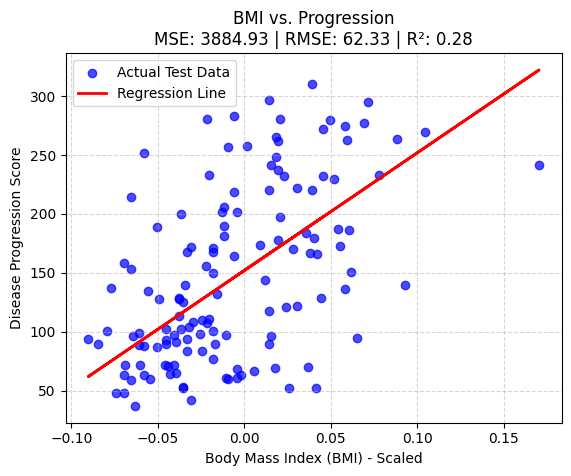

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# 1. Generate predictions for the test data
y_pred = model.predict(X_test)

# 2. Calculate the exact error metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# 3. Plot the actual test data points
plt.scatter(X_test, y_test, color='blue', alpha=0.7, label='Actual Test Data')

# 4. Plot the regression line
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Regression Line')

# 5. Format labels and display the errors directly in the title
plt.title(f'BMI vs. Progression\nMSE: {mse:.2f} | RMSE: {rmse:.2f} | R²: {r2:.2f}')
plt.xlabel('Body Mass Index (BMI) - Scaled')
plt.ylabel('Disease Progression Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# 6. Show the plot
plt.show()


In [ ]:
y_pred=lr.predict(X_test)
print(y_pred)
#

In [ ]:
from sklearn.linear_model import LinearRegression

# 1. Instantiate the model object (create your calculator tool)
model = LinearRegression()

# 2. Fit the model using your training data (train your tool)
model.fit(X_train, y_train)

print("Model training complete!")
print(f"Slope (m): {model.coef_}")
print(f"Intercept (c): {model.intercept_:.2f}")


Model training complete!
Slope (m): [998.57768914]
Intercept (c): 152.00
